In [1]:

import numpy as np
from numpy.typing import NDArray
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.figure import Figure
from matplotlib.axes import Axes
import astropy.units as u
from astropy.io import fits
from astropy.wcs import WCS
from astropy.time import Time
from astropy.nddata import Cutout2D
from astropy.stats import sigma_clipped_stats
from astropy.coordinates import SkyCoord, EarthLocation, Angle, get_body_barycentric
from photutils.segmentation import detect_sources, SegmentationImage, SourceCatalog
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares, OptimizeResult
import os
BOX_SIZE = 200

In [2]:
os.chdir("/home/odin/Code/Course-Assignments/PH556_Astrophysics/Attempt01/data/")
print("Current working directory: {0}".format(os.getcwd()))
allDataFileNames = os.listdir()
# print("Files in current working directory: {0}".format(allDataFileNames))
print(allDataFileNames)

files = [fits.open(filename) for filename in allDataFileNames]
# fileData = [file[0].data for file in files]
# fileHeaders = [file[0].header for file in files]

Current working directory: /home/odin/Code/Course-Assignments/PH556_Astrophysics/Attempt01/data
['20210721192429-359-RA.wcs.proc.fits', '20210721191920-421-RA.wcs.proc.fits', '20210713215458-181-RA.wcs.proc.fits', '20210721193447-216-RA.wcs.proc.fits', '20210721191411-345-RA.wcs.proc.fits', '20210713220516-046-RA.wcs.proc.fits', '20210721194505-080-RA.wcs.proc.fits', '20210713213912-742-RA.wcs.proc.fits', '20210713214440-179-RA.wcs.proc.fits', '20210713214949-265-RA.wcs.proc.fits', '20210713221024-980-RA.wcs.proc.fits', '20210714213919-746-RA.wcs.proc.fits', '20210713221533-914-RA.wcs.proc.fits', '20210721195014-013-RA.wcs.proc.fits', '20210714220020-444-RA.wcs.proc.fits']


In [3]:
# '2021-07-21T19:24:29.359'

def parseOBSDate(dateString):
    res1 = dateString.split("T")
    resMajor = res1[0].split("-")
    resMinor = res1[1].split(":")
    res = [float(x) for x in resMajor + resMinor]
    numVal = res[0]*(12*31)*24*60*60 + res[1]*31*24*60*60 + res[2]*24*60*60 + res[3]*60*60 + res[4]*60 + res[5]
    return [res, numVal]

def addTime(res, numVal, dtInSeconds):
    numValNew = numVal + dtInSeconds
    resNew = [0, 0, 0, 0, 0, 0]
    resNew[0] = res[0]
    resNew[1] = res[1]
    resNew[2] = res[2]
    resNew[3] = res[3]
    resNew[4] = res[4]
    resNew[5] = res[5] + dtInSeconds
    if resNew[5] >= 60:
        resNew[4] += int(resNew[5]/60)
        resNew[5] = resNew[5]%60
    if resNew[4] >= 60:
        resNew[3] += int(resNew[4]/60)
        resNew[4] = resNew[4]%60
    if resNew[3] >= 24:
        resNew[2] += int(resNew[3]/24)
        resNew[3] = resNew[3]%24
    if resNew[2] > 31:
        resNew[1] += int(resNew[2]/31)
        resNew[2] = resNew[2]%31
    if resNew[1] > 12:
        resNew[0] += int(resNew[1]/12)
        resNew[1] = resNew[1]%12
    return [resNew, numValNew]

In [4]:
datesOfObservationParsed = [parseOBSDate(file[0].header['DATE-OBS']) for file in files]
datesOfObservationNumVal = [date[1] for date in datesOfObservationParsed]
datesOfObservationDateVal = [date[0] for date in datesOfObservationParsed]
indicesForDateSortingAscending = np.argsort(datesOfObservationNumVal)

In [5]:
filesAscendingDate = [files[i] for i in indicesForDateSortingAscending]
dataValsArranged = [file[0].data for file in filesAscendingDate]
headerValsArranged = [file[0].header for file in filesAscendingDate]

In [6]:
(Time(files[1][0].header['DATE-OBS'],scale='utc') + files[1][0].header['EXPTIME']*u.s/2).jd

np.float64(2459417.3068335764)

In [7]:
bin1Files = filesAscendingDate[0:7]
bin2Files = filesAscendingDate[7:9]
bin3Files = filesAscendingDate[9:15]
bins = [bin1Files, bin2Files, bin3Files]
binRanges = [[i for i in range(0,7)], [i for i in range(7,9)], [i for i in range(9,15)]]
binRanges

[[0, 1, 2, 3, 4, 5, 6], [7, 8], [9, 10, 11, 12, 13, 14]]

In [8]:
def getMidExposureTime(file):
    dateObs = file[0].header['DATE-OBS']
    exptime = file[0].header['EXPTIME']
    midExposureTime = (Time(dateObs, scale='utc') + exptime*u.s/2).jd
    return midExposureTime

midExposureTimes = [getMidExposureTime(filesAscendingDate[i]) for i in range(len(filesAscendingDate))]

In [9]:
RAVals = [headerValsArranged[i]['TARRA'] for i in range(len(headerValsArranged))]
DecVals = [headerValsArranged[i]['TARDEC'] for i in range(len(headerValsArranged))]


In [10]:
def subsetTakeAndFilter(file, centerRA, centerDec, size = BOX_SIZE):
    data = file[0].data
    header = file[0].header
    wcs = WCS(header)
    subset = Cutout2D(data, position=SkyCoord(centerRA, centerDec, unit=(u.deg, u.deg)), size=(size, size), wcs=wcs)
    _, sky, sigma = sigma_clipped_stats(subset.data)
    return subset.data - sky, subset.wcs, float(sigma)


def find_sources(img, sigma: float, nsigma: float = 3.0,
                 npix: int = 8):
    '''Pixel (x, y) centres of all blobs with >= npix connected pixels above nsigma*sigma.'''
    seg: SegmentationImage | None = detect_sources(img, nsigma * sigma, npix)
    if seg is None:                                           # nothing above threshold
        return np.array([]), np.array([])
    cat: SourceCatalog = SourceCatalog(img, seg)
    return np.asarray(cat.xcentroid, float), np.asarray(cat.ycentroid, float)


def predicted_position(hdr0: fits.Header, t0: Time, t: Time) -> SkyCoord:
    dt_hr: float = (t - t0).to_value(u.hour)
    ra: float = hdr0['TARRA'] + float(hdr0['DRATERA']) * dt_hr    
    dec: float = hdr0['TARDEC'] + float(hdr0['DRATEDEC']) * dt_hr
    return SkyCoord(ra, dec, unit='deg')


In [11]:
CENTROID_R: float = 6.0
def centroid(img, x: float, y: float, r: float = CENTROID_R,
             n_iter: int = 5) -> tuple[float, float]:
    '''Iterative flux-weighted centroid inside a circle of radius r around (x, y). Pixel units.'''
    yy: NDArray[np.intp]
    xx: NDArray[np.intp]
    yy, xx = np.indices(img.shape)                  # pixel coordinate grids, each (ny, nx)
    for _ in range(n_iter):
        inside = (xx - x)**2 + (yy - y)**2 <= r**2     # (ny, nx) mask
        w: Image = np.clip(img * inside, 0, None)   # negative (noise) pixels get zero weight
        x, y = float((w * xx).sum() / w.sum()), float((w * yy).sum() / w.sum())
    return x, y

In [12]:
subsetImageData = []
subsetImageWCS = []
subsetImageSigma = []
subsetImagesSources = []

# cut out, clean and find sources in every file (all files first, because a frame needs its far frame already processed)
for fileIdx in range(len(filesAscendingDate)):
    imgData, fileWCS, sigma = subsetTakeAndFilter(filesAscendingDate[fileIdx], RAVals[fileIdx], DecVals[fileIdx], size=BOX_SIZE)
    xs, ys = find_sources(imgData, sigma)
    subsetImageData.append(imgData)
    subsetImageWCS.append(fileWCS)
    subsetImageSigma.append(sigma)
    subsetImagesSources.append(fileWCS.pixel_to_world(xs, ys))


In [13]:
STAR_MOVEMENT_THRESHOLD = 2.0*u.arcsec
ASTEROID_SEARCH_RADIUS = 5

asteroidPositions = []
asteroidDetectedFlags = []
asteroidOffsetFromPrediction = []

for nightIdx in range(len(binRanges)):
    firstIdx = binRanges[nightIdx][0]
    lastIdx = binRanges[nightIdx][-1]
    # TARRA/TARDEC refer to the start of the night's first exposure
    nightStartTime = Time(headerValsArranged[firstIdx]['DATE-OBS'], scale='utc')

    for fileIdx in binRanges[nightIdx]:
        currentMidExposureTime = midExposureTimes[fileIdx]

        # compare against whichever end of the night is further away in time
        if (currentMidExposureTime - midExposureTimes[firstIdx]) > (midExposureTimes[lastIdx] - currentMidExposureTime):
            indexOfFarthestExposureTime = firstIdx
        else:
            indexOfFarthestExposureTime = lastIdx

        skyWCS = subsetImagesSources[fileIdx]
        _, d_far, _ = skyWCS.match_to_catalog_sky(subsetImagesSources[indexOfFarthestExposureTime])
        isPixelMoving = d_far > STAR_MOVEMENT_THRESHOLD

        predictedAsteroidPos = predicted_position(headerValsArranged[firstIdx], nightStartTime, Time(currentMidExposureTime, format='jd', scale='utc'))
        nearbyPixelDistances = skyWCS.separation(predictedAsteroidPos).arcsec
        nearbyPixelDistances[~isPixelMoving] = np.inf
        closestSourceIdx = int(np.argmin(nearbyPixelDistances)) if len(nearbyPixelDistances) > 0 else None
        asteroidDetected = closestSourceIdx is not None and nearbyPixelDistances[closestSourceIdx] < ASTEROID_SEARCH_RADIUS
        asteroidLocationEstimate = skyWCS[closestSourceIdx] if asteroidDetected else predictedAsteroidPos

        ax0, ay0 = subsetImageWCS[fileIdx].world_to_pixel(asteroidLocationEstimate)
        x, y = centroid(subsetImageData[fileIdx], float(ax0), float(ay0))
        pos = subsetImageWCS[fileIdx].pixel_to_world(x, y)

        asteroidPositions.append(pos)
        asteroidDetectedFlags.append(bool(asteroidDetected))
        asteroidOffsetFromPrediction.append(float(pos.separation(predictedAsteroidPos).arcsec))


In [14]:
astro = pd.DataFrame({
    'night': [headerValsArranged[i]['DATE-OBS'][:10] for i in range(len(headerValsArranged))],
    'utc_mid': [Time(t, format='jd', scale='utc').iso for t in midExposureTimes],
    'jd_utc': midExposureTimes,
    'ra_deg': [float(p.ra.deg) for p in asteroidPositions],
    'dec_deg': [float(p.dec.deg) for p in asteroidPositions],
    'detected': asteroidDetectedFlags,
    'off_pred_arcsec': asteroidOffsetFromPrediction,
})
astro.to_csv('../output/astrometry_refined.csv', index=False, float_format='%.8f')
astro.round(6)


,night,utc_mid,jd_utc,ra_deg,dec_deg,detected,off_pred_arcsec
0,2021-07-13,2021-07-13 21:41:42.742,2.459409e+06,1.832797,0.817900,True,3.293705
1,2021-07-13,2021-07-13 21:47:10.179,2.459409e+06,1.833310,0.818161,True,3.168572
2,2021-07-13,2021-07-13 21:52:19.265,2.459409e+06,1.833825,0.818379,True,3.130861
3,2021-07-13,2021-07-13 21:57:28.181,2.459409e+06,1.834346,0.818642,True,3.158157
4,2021-07-13,2021-07-13 22:07:46.046,2.459409e+06,1.835328,0.819082,True,2.930424
5,2021-07-13,2021-07-13 22:12:54.980,2.459409e+06,1.835740,0.819282,True,2.530812
6,2021-07-13,2021-07-13 22:18:03.914,2.459409e+06,1.836249,0.819547,True,2.513019
7,2021-07-14,2021-07-14 21:41:49.746,2.459410e+06,1.979627,0.881189,True,0.787016
8,2021-07-14,2021-07-14 22:02:50.444,2.459410e+06,1.981557,0.882134,True,1.491265
9,2021-07-21,2021-07-21 19:16:41.345,2.459417e+06,2.841206,1.251704,True,0.800650


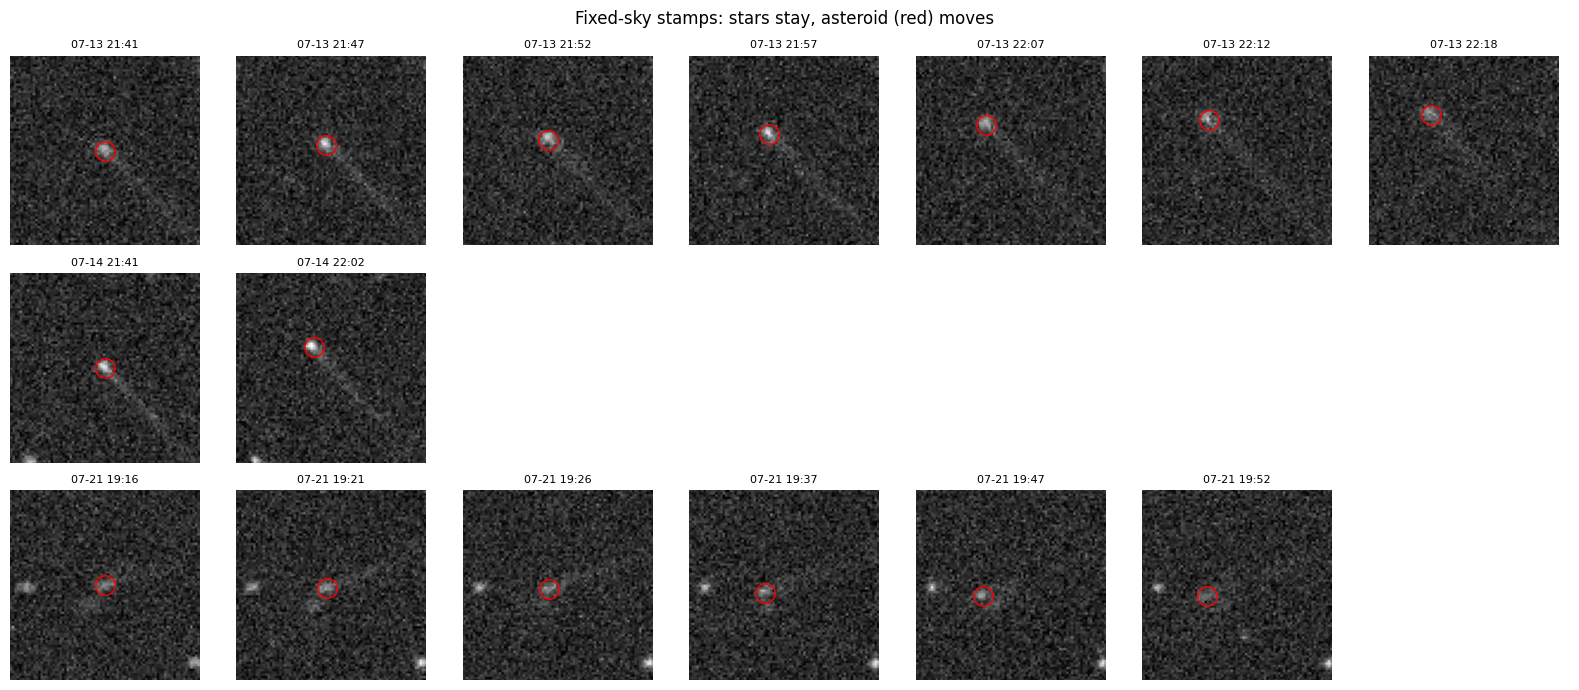

In [15]:
# picture check: every stamp in a row is centred on the same sky spot, so stars stay put and the asteroid (red) moves
STAMP_HALF = 40

fig, axs = plt.subplots(len(binRanges), 7, figsize=(16, 7))
for ax in axs.ravel():
    ax.axis('off')

for nightIdx in range(len(binRanges)):
    anchor = asteroidPositions[binRanges[nightIdx][0]]
    for col, fileIdx in enumerate(binRanges[nightIdx]):
        cx, cy = subsetImageWCS[fileIdx].world_to_pixel(anchor)
        astX, astY = subsetImageWCS[fileIdx].world_to_pixel(asteroidPositions[fileIdx])
        ax = axs[nightIdx, col]
        ax.imshow(subsetImageData[fileIdx], origin='lower', cmap='gray',
                  vmin=-2*subsetImageSigma[fileIdx], vmax=10*subsetImageSigma[fileIdx])
        ax.plot(astX, astY, 'o', mfc='none', mec='r', ms=14)
        ax.set_xlim(cx - STAMP_HALF, cx + STAMP_HALF)
        ax.set_ylim(cy - STAMP_HALF, cy + STAMP_HALF)
        ax.set_title(astro['utc_mid'][fileIdx][5:16], fontsize=8)

fig.suptitle('Fixed-sky stamps: stars stay, asteroid (red) moves')
fig.tight_layout()
plt.show()
